# Word2Vec · the CBOW model
## Continuous Bag-of-Words — theory, architecture, a from-scratch PyTorch implementation, the Gensim reference, and the limits that lead to Skip-gram

> *"You shall know a word by the company it keeps."* — J. R. Firth (1957)

**Level:** graduate NLP / representation learning  **Prerequisites:** softmax & cross-entropy, back-propagation, basic PyTorch  **Runtime:** a few minutes on a laptop CPU, no download needed

---

### Abstract

This notebook is a self-contained study of **CBOW**, the first of the two architectures of Word2Vec (Mikolov et al., 2013a, 2013b). We

1. motivate dense, distributed word representations and place Word2Vec in the history of neural language modelling;
2. **derive** the CBOW objective, its gradients and its computational cost;
3. draw and analyse the **architecture**, with tensor shapes;
4. verify the maths with a from-scratch **NumPy** implementation (analytic gradients vs. finite differences);
5. implement CBOW in **PyTorch** — full-softmax and negative-sampling versions, subsampling, dynamic window;
6. reproduce the model with the production library **Gensim** and compare the three implementations;
7. study experimentally the **structural limits of CBOW** — order blindness, the averaging bottleneck, weak signal for rare words, polysemy, out-of-vocabulary words, softmax cost;
8. use those limits to **open the door to Skip-gram**, the subject of the next notebook.

### Contents

| § | Title |
|---|-------|
| 0 | Setup |
| 1 | From the distributional hypothesis to dense vectors |
| 2 | CBOW — mathematical formulation |
| 3 | Architecture and tensor shapes |
| 4 | Worked example in NumPy: forward, backward, gradient check |
| 5 | Making the softmax tractable: hierarchical softmax, negative sampling, subsampling |
| 6 | Data: a synthetic corpus with known ground truth |
| 7 | Implementation in PyTorch |
| 8 | Implementation with Gensim |
| 9 | Side-by-side comparison |
| 10 | **Limits of CBOW** (six experiments) |
| 11 | **Opening: Skip-gram** |
| 12 | Exercises and references |

> **Why a synthetic corpus?** Real corpora (text8, Wikipedia) require a download and give only *qualitative* evidence. Here the semantic structure is planted on purpose (animals, fruits, vehicles, countries/capitals, gender pairs, one polysemous word, a few very rare words), so every claim — "A is close to B", "the analogy works" — is **measured against ground truth**. §12 explains how to rerun everything on text8.

## 0 · Setup

In [3]:
!pip install -q gensim

# If needed:   pip install torch gensim numpy pandas matplotlib scikit-learn
import math, random, time, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import gensim
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print(f"torch {torch.__version__} | gensim {gensim.__version__} | device = {device}")

torch 2.11.0+cpu | gensim 4.4.0 | device = cpu


# Introduction 

CBoW (**Continuous Bag of Words**) is of the first model described by in the word2vec paper.

Given several surrounding context words, predict the center word that belongs in the middle. 
CBOW trains faster, scales better to large corpora, and produces stronger embeddings for frequent words

Think about fill-in-the-blanks task : "The cat __ on my lap. Given the surrounding words, one can immediatly guess "sits". The brain uses the information provided by the context words and their collective signals to identify what fits in the middle ; that's excatly what CBoW models computationally.

> The CBOW model learns word representations by training a neural network to predict a center (target) word from its surrounding context words. All context word embeddings are averaged into a single representation before making the prediction. The learned embedding matrix becomes the word embeddings.

As for the meaning behind the name CBow : 
- **Continuous** refers to the use of continuous-valued dense vectors rather than discrete one-hot encodings 
- **Bags of words** highlights the fact that the model treats context as unordered collection : it cannot distinguish between a word appearing two position to the left and one appearing one position on the right ; both are simply "context words". this positional difference is a design choice to simplify modeling and reduce the complexity i.e number of parameters, of course with a certain cost that will be talked in the limits at the end


## 1 · From the distributional hypothesis to dense vectors

### 1.1 The representation problem
To feed words to a learning algorithm we need vectors. The naive choice is the **one-hot** vector $e_w\in\{0,1\}^V$ ($V$ = vocabulary size, typically $10^5$–$10^6$). It has two fatal defects:

* **no similarity:** $e_i^\top e_j=0$ for $i\neq j$ — *cat* is exactly as far from *dog* as from *carburetor*;
* **no sharing of statistical strength:** what is learned about *cat* tells us nothing about *dog*, and the dimension $V$ makes every downstream model huge.

### 1.2 The distributional hypothesis
Harris (1954) and Firth (1957) proposed that the **meaning of a word is reflected in the distribution of the contexts in which it occurs**. Words used in similar contexts (*cat*, *dog*) should therefore receive similar representations. Two families operationalise this idea:

* **count-based** methods build a word–context co-occurrence matrix and factorise it (LSA, PPMI + SVD);
* **predictive** methods *learn* the vectors by training a model to predict words from their contexts (or vice-versa).

### 1.3 From neural language models to Word2Vec
Bengio et al. (2003) learned embeddings jointly with a neural *next-word* predictor: embeddings → concatenation → non-linear hidden layer → softmax over $V$. It worked but was far too slow for large corpora. Mikolov et al. (2013a) observed that the embeddings — not the language model — were the prize, and therefore **removed the non-linear hidden layer, dropped the word order, and used words on both sides of the target**. The result is two shallow log-linear models trainable on billions of tokens:

| | input → output | idea |
|---|---|---|
| **CBOW** (this notebook) | context words → centre word | "fill in the blank" |
| **Skip-gram** (§11, next notebook) | centre word → each context word | "guess the neighbours" |

### 1.4 Notation

| symbol | meaning |
|---|---|
| $\mathcal V$, $V=\lvert\mathcal V\rvert$ | vocabulary and its size |
| $d$ | embedding dimension (typically 100–300) |
| $w_1,\dots,w_T$ | the corpus, $T$ tokens |
| $c$ | (maximal) window radius |
| $C_t=\{w_{t+j}: -c\le j\le c,\ j\neq0\}$ | context of position $t$;  $n_t=\lvert C_t\rvert\le 2c$ |
| $W\in\mathbb R^{V\times d}$ | **input** embedding matrix; row $v_w$ is the *input vector* of word $w$ |
| $W'\in\mathbb R^{d\times V}$ | **output** matrix; column $u_w$ is the *output vector* of $w$. In code we store $U=W'^{\top}\in\mathbb R^{V\times d}$ |
| $h_t\in\mathbb R^{d}$ | hidden (context) vector |
| $\sigma(x)=1/(1+e^{-x})$ | sigmoid |

## 2 · CBOW — mathematical formulation

### 2.1 The task
Given the words around a position $t$, predict the word at $t$:

$$\text{“the } \underline{\;\;?\;\;}\text{ runs in the field”}\ \longrightarrow\ \textit{cat}$$

The word *continuous* refers to the distributed (real-valued) representation; the word *bag* to the fact that the **context is treated as an unordered multiset**: positions are forgotten.

### 2.2 The model
**(1) Context vector** — average the input vectors of the context words:

$$h_t=\frac1{n_t}\sum_{w\in C_t}v_w .$$

**(2) Scores and softmax** — score every candidate word $k$ with its output vector and normalise:

$$z_k=u_k^{\top}h_t,\qquad
\hat y_k \;=\; p(w_t=k\mid C_t)\;=\;\frac{\exp(z_k)}{\sum_{j=1}^{V}\exp(z_j)} .$$

**(3) Objective** — maximise the log-likelihood of the corpus, i.e. minimise the cross-entropy between the one-hot target and $\hat y$:

$$\mathcal J(W,U)\;=\;-\frac1T\sum_{t=1}^{T}\log p(w_t\mid C_t)\;=\;-\frac1T\sum_{t=1}^{T}\Big[\,u_{w_t}^{\top}h_t-\log\sum_{j=1}^{V}e^{u_j^{\top}h_t}\Big].$$

### 2.3 Compact matrix form
Let $\bar x_t=\frac1{n_t}\sum_{w\in C_t}e_w$ be the (normalised) **bag-of-words vector** of the context. Then

$$h_t=W^{\top}\bar x_t,\qquad \hat y_t=\operatorname{softmax}\!\big(U\,W^{\top}\bar x_t\big).$$

Three structural observations:

1. **There is no hidden non-linearity.** Everything before the softmax is linear: CBOW is a *log-bilinear* classifier, $\log p(k\mid C)=u_k^{\top}W^{\top}\bar x-\log Z$.
2. **Low-rank factorisation.** The matrix of logits $UW^{\top}\in\mathbb R^{V\times V}$ has rank $\le d$: CBOW factorises a "word-given-context" score table through a $d$-dimensional bottleneck. This is why embeddings capture similarity at all.
3. **Two vectors per word:** $v_w$ (word as *context*) and $u_w$ (word as *target*). Usually $v_w$ is kept as "the" embedding; averaging $v_w$ and $u_w$ is also common.

### 2.4 Gradients (derivation)
For one example with one-hot target $y$ and loss $L=-\log\hat y_{y}$:

$$\frac{\partial L}{\partial z}=\hat y-y,\qquad
\frac{\partial L}{\partial u_k}=(\hat y_k-y_k)\,h,\qquad
\frac{\partial L}{\partial h}=\sum_{k}(\hat y_k-y_k)\,u_k=U^{\top}(\hat y-y),$$

and, because $h$ is an average, **each occurrence** of a word $w$ in the context receives

$$\frac{\partial L}{\partial v_w}=\frac1{n_t}\,\frac{\partial L}{\partial h}.$$

*Interpretation (Rong, 2014).* A gradient step gives
$u_k\leftarrow u_k-\eta(\hat y_k-y_k)h$: the target's output vector is pulled towards $h$, every other output vector is pushed away from $h$ in proportion to the probability the model wrongly gave it. The context vectors move by
$\Delta v_w\propto\frac1{n_t}\big(u_{w_t}-\mathbb E_{k\sim\hat y}[u_k]\big)$: **towards the true target's output vector and away from the model's expected output vector** — all context words of one window move *together, by the same amount*.

### 2.5 Cost
Per training example: $O(n_t d)$ for the average, $O(Vd)$ for the $V$ scores, $O(V)$ for the softmax, and the same for the backward pass. **The output layer, $O(Vd)$, dominates.** The model has $2Vd$ parameters (e.g. $V=10^6,\ d=300$ → $6\times10^8$ floats ≈ 2.4 GB). This is the practical bottleneck that §5 removes.

## 3 · Architecture and tensor shapes

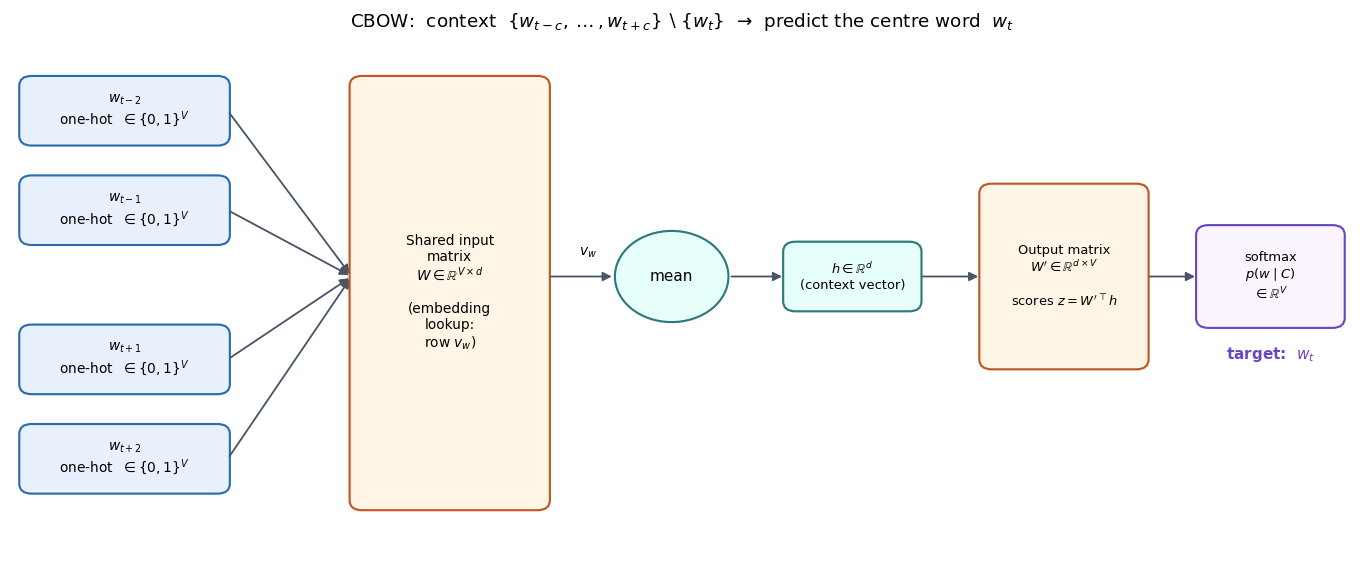

In [4]:
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

def _box(ax, x, y, w, h, text, fc="#E8F1FB", ec="#2B6CB0", fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def _arrow(ax, p, q, color="#4A5568"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=12, lw=1.2, color=color))

def draw_architecture(kind="cbow"):
    """Schematic of the two Word2Vec architectures (window radius c = 2)."""
    fig, ax = plt.subplots(figsize=(12.5, 5.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")
    ys = [4.9, 3.7, 1.9, 0.7]
    names = [r"$w_{t-2}$", r"$w_{t-1}$", r"$w_{t+1}$", r"$w_{t+2}$"]
    if kind == "cbow":
        for y, n in zip(ys, names):
            _box(ax, 0.1, y, 2.0, 0.8, n + "\none-hot  $\\in\\{0,1\\}^V$")
            _arrow(ax, (2.1, y + 0.4), (3.3, 3.3))
        _box(ax, 3.3, 0.5, 1.9, 5.2, "Shared input\nmatrix\n$W\\in\\mathbb{R}^{V\\times d}$\n\n(embedding\nlookup:\nrow $v_w$)", fc="#FFF5E6", ec="#C05621")
        ax.add_patch(Circle((6.4, 3.3), 0.55, fc="#E6FFFA", ec="#2C7A7B", lw=1.4)); ax.text(6.4, 3.3, "mean", ha="center", va="center", fontsize=10)
        _arrow(ax, (5.2, 3.3), (5.85, 3.3)); ax.text(5.5, 3.55, "$v_w$", fontsize=9)
        _arrow(ax, (6.95, 3.3), (7.5, 3.3))
        _box(ax, 7.5, 2.9, 1.3, 0.8, "$h\\in\\mathbb{R}^d$\n(context vector)", fc="#E6FFFA", ec="#2C7A7B", fs=8.5)
        _arrow(ax, (8.8, 3.3), (9.4, 3.3))
        _box(ax, 9.4, 2.2, 1.6, 2.2, "Output matrix\n$W'\\in\\mathbb{R}^{d\\times V}$\n\nscores $z=W'^{\\top}h$", fc="#FFF5E6", ec="#C05621", fs=8.5)
        _arrow(ax, (11.0, 3.3), (11.5, 3.3))
        _box(ax, 11.5, 2.7, 1.4, 1.2, "softmax\n$p(w\\mid C)$\n$\\in\\mathbb{R}^V$", fc="#FAF5FF", ec="#6B46C1", fs=8.5)
        ax.text(12.2, 2.3, "target:  $w_t$", ha="center", fontsize=10, color="#6B46C1", fontweight="bold")
        ax.set_title("CBOW:  context  $\\{w_{t-c},\\dots,w_{t+c}\\}\\setminus\\{w_t\\}$  →  predict the centre word  $w_t$", fontsize=12)
    else:
        _box(ax, 0.1, 2.9, 2.0, 0.8, "$w_t$\none-hot  $\\in\\{0,1\\}^V$"); _arrow(ax, (2.1, 3.3), (3.0, 3.3))
        _box(ax, 3.0, 2.2, 1.9, 2.2, "Input matrix\n$W\\in\\mathbb{R}^{V\\times d}$\n\n(lookup: row $v_{w_t}$)", fc="#FFF5E6", ec="#C05621", fs=8.5)
        _arrow(ax, (4.9, 3.3), (5.6, 3.3))
        _box(ax, 5.6, 2.9, 1.3, 0.8, "$h=v_{w_t}$\n$\\in\\mathbb{R}^d$", fc="#E6FFFA", ec="#2C7A7B", fs=8.5)
        _arrow(ax, (6.9, 3.3), (7.5, 3.3))
        _box(ax, 7.5, 2.2, 1.7, 2.2, "Output matrix\n$W'\\in\\mathbb{R}^{d\\times V}$\n(shared by all\ncontext slots)", fc="#FFF5E6", ec="#C05621", fs=8.5)
        _arrow(ax, (9.2, 3.3), (9.8, 3.3))
        _box(ax, 9.8, 2.8, 1.3, 1.0, "softmax\n$p(\\cdot\\mid w_t)$", fc="#FAF5FF", ec="#6B46C1", fs=8.5)
        for y, n in zip(ys, names):
            _arrow(ax, (11.1, 3.3), (11.6, y + 0.4), color="#6B46C1")
            _box(ax, 11.6, y, 1.3, 0.8, n, fc="#FAF5FF", ec="#6B46C1")
        ax.set_title("Skip-gram:  centre word  $w_t$  →  predict each context word  $w_{t+j}$", fontsize=12)
    plt.tight_layout(); plt.show()

draw_architecture("cbow")

**Reading the figure.** The $2c$ context words are looked up in the *same* matrix $W$ (weight sharing), averaged into a single $d$-dimensional vector $h$, and $h$ is projected by the output matrix $W'$ onto $V$ scores, which a softmax turns into a distribution over the vocabulary. The supervision signal is the centre word $w_t$.

| stage | operation | tensor shape (batch $B$, $2c$ context slots) | parameters |
|---|---|---|---|
| input | context indices (long) | $(B,\,2c)$ | – |
| embedding lookup | $W[\text{ctx}]$  (≡ one-hot × $W$) | $(B,\,2c,\,d)$ | $Vd$ |
| masked mean | $\sum_j m_j v_j\,/\,\sum_j m_j$ | $(B,\,d)$ | 0 |
| output scores | $h\,U^{\top}$ | $(B,\,V)$ | $Vd$ |
| softmax + NLL | cross-entropy with centre word | scalar | 0 |

**Practical remarks.**
* *One-hot × matrix = row lookup*, so we never build one-hot vectors: `nn.Embedding` does it in $O(d)$.
* Windows are truncated at sentence boundaries, hence **padding + a mask** so that the mean runs only over real context words.
* There are **no biases and no non-linearities** in the original model.

## 4 · Worked example in NumPy: forward, backward, gradient check

Before using any framework, we implement CBOW's forward and backward passes by hand on a 5-word vocabulary and check the gradients derived in §2.4 against **central finite differences**. The context deliberately contains *the* twice, to exercise the "each occurrence receives $\frac1{n_t}\partial L/\partial h$" rule.

In [5]:
# ---- Toy example:  "the cat sat on the mat",  centre word = "sat",  window c = 2 --------------------
toy_vocab = ["the", "cat", "sat", "on", "mat"]
toy_i = {w: i for i, w in enumerate(toy_vocab)}
toyV, toyD = len(toy_vocab), 3

rs = np.random.default_rng(0)
toy_W  = rs.normal(0, 0.5, (toyV, toyD))      # input vectors  v_w  (one row per word)
toy_U  = rs.normal(0, 0.5, (toyV, toyD))      # output vectors u_w  (rows of W'^T)
toy_ctx = np.array([toy_i[w] for w in ["the", "cat", "on", "the"]])   # NB: "the" occurs twice
toy_y   = toy_i["sat"]

def cbow_forward(W, U, ctx, y):
    h = W[ctx].mean(axis=0)                   # (d,)    average of the context vectors
    z = U @ h                                 # (V,)    scores  z_k = u_k . h
    z = z - z.max()                           #         numerical stability
    p = np.exp(z) / np.exp(z).sum()           # (V,)    softmax
    return h, p, -np.log(p[y])                #         loss = -log p(w_t | C)

def cbow_backward(W, U, ctx, y):
    h, p, loss = cbow_forward(W, U, ctx, y)
    dz = p.copy(); dz[y] -= 1.0               # dL/dz   = p - onehot(y)
    dU = np.outer(dz, h)                      # dL/du_k = (p_k - y_k) h            -> every output vector moves
    dh = U.T @ dz                             # dL/dh   = sum_k (p_k - y_k) u_k
    dW = np.zeros_like(W)
    np.add.at(dW, ctx, dh / len(ctx))         # dL/dv_w = (1/n) dL/dh  per occurrence in the context
    return loss, dW, dU

def numerical_grad(f, X, eps=1e-6):           # central finite differences
    G = np.zeros_like(X)
    for idx in np.ndindex(*X.shape):
        old = X[idx]
        X[idx] = old + eps; lp = f()
        X[idx] = old - eps; lm = f()
        X[idx] = old;       G[idx] = (lp - lm) / (2 * eps)
    return G

loss, dW, dU = cbow_backward(toy_W, toy_U, toy_ctx, toy_y)
loss_fn = lambda: cbow_forward(toy_W, toy_U, toy_ctx, toy_y)[2]
print(f"loss = {loss:.4f}   (a uniform guess would give log V = {np.log(toyV):.4f})")
print("max |analytic - numeric|  for dL/dW :", np.abs(dW - numerical_grad(loss_fn, toy_W)).max())
print("max |analytic - numeric|  for dL/dU :", np.abs(dU - numerical_grad(loss_fn, toy_U)).max())
print("\nrows of dL/dW that are non-zero ->", [toy_vocab[i] for i in np.flatnonzero(np.abs(dW).sum(1))],
      "  ('sat' and 'mat' get NO gradient on their input vectors: they are not in the context)")
print("update size of 'the' relative to 'cat':", round(np.linalg.norm(dW[toy_i['the']]) / np.linalg.norm(dW[toy_i['cat']]), 3),
      " (= 2: it occurs twice in the window)")

loss = 1.5808   (a uniform guess would give log V = 1.6094)
max |analytic - numeric|  for dL/dW : 1.854073561347036e-10
max |analytic - numeric|  for dL/dU : 1.5248020554525787e-10

rows of dL/dW that are non-zero -> ['the', 'cat', 'on']   ('sat' and 'mat' get NO gradient on their input vectors: they are not in the context)
update size of 'the' relative to 'cat': 2.0  (= 2: it occurs twice in the window)


**What this shows.** (i) The analytic gradients agree with numerical differentiation to ~$10^{-10}$, so §2.4 is right. (ii) Only the **context** words receive a gradient on their *input* vectors — the target does not — but **all $V$ output vectors** receive one (this is the $O(Vd)$ cost). (iii) A word that appears twice in the window is updated twice as strongly: the bag is a *multiset*.

## 5 · Making the softmax tractable

The exact softmax normalises over all $V$ words, so each example costs $O(Vd)$. Mikolov et al. (2013a, 2013b) proposed three tricks that make training on $10^{9}$–$10^{11}$ tokens possible.

### 5.1 Hierarchical softmax (Morin & Bengio, 2005)
Arrange the vocabulary as the leaves of a binary (Huffman) tree. The probability of a word is the product of $L(w)-1\approx\log_2 V$ binary decisions along its root-to-leaf path, each a sigmoid of $h$ with a vector attached to an *inner node*:

$$p(w\mid h)=\prod_{j=1}^{L(w)-1}\sigma\!\big(\llbracket \text{step } j \text{ goes left}\rrbracket\;\, v'^{\top}_{n(w,j)}\,h\big),$$

where $\llbracket\cdot\rrbracket=\pm1$. Cost: $O(d\log V)$. Huffman coding gives frequent words short paths. In Gensim: `hs=1`.

### 5.2 Negative sampling (Mikolov et al., 2013b)
Abandon the normalised probability altogether and train a **binary logistic classifier** that separates the true target from $K$ noise words drawn from a distribution $P_n$:

$$\ell_t\;=\;-\log\sigma\!\big(u_{w_t}^{\top}h_t\big)\;-\;\sum_{i=1}^{K}\mathbb E_{w_i\sim P_n}\Big[\log\sigma\!\big(-u_{w_i}^{\top}h_t\big)\Big],\qquad P_n(w)\propto f(w)^{3/4}.$$

The $3/4$ power flattens the unigram distribution, so rare words are sampled more often than their frequency suggests. Typical $K=5\text{–}20$ for small corpora and $2\text{–}5$ for large ones. Cost: $O(Kd)$, independent of $V$. It is a simplification of Noise-Contrastive Estimation (Gutmann & Hyvärinen, 2010); note that it is **no longer a normalised language model** — only the embeddings matter. In Gensim: `negative=K` (and `ns_exponent=0.75`).

### 5.3 Sub-sampling of frequent words
Words such as *the* or *of* carry little information but dominate the counts. Each token $w$ is **discarded** with probability

$$P(\text{discard }w)=1-\sqrt{\frac{t}{f(w)}},\qquad f(w)=\frac{\text{count}(w)}{T},\quad t\approx10^{-5}\ldots10^{-3}.$$

This speeds training up and improves the vectors of less frequent words. (Gensim's `sample=t` uses a slightly different but similar formula.)

### 5.4 Dynamic window
For each centre word the effective radius $b$ is drawn uniformly from $\{1,\dots,c\}$. A neighbour at distance $|j|$ is thus included with probability $(c-|j|+1)/c$: **closer words count more**, at no extra cost. (Gensim ≥ 4.1: `shrink_windows=True`, the default.)

### 5.5 Learning rate
The reference C code uses plain SGD, one example at a time (asynchronous "Hogwild" threads), starting at $\alpha_0=0.05$ for CBOW and $0.025$ for Skip-gram and decaying linearly to ~0 ($\alpha_0=0.025$ in Gensim by default).

| objective | cost / example | normalised? | Gensim |
|---|---|---|---|
| full softmax | $O(Vd)$ | yes | – (not offered) |
| hierarchical softmax | $O(d\log V)$ | yes | `hs=1` |
| negative sampling | $O(Kd)$ | no | `negative=K` |

## 6 · Data: a synthetic corpus with known ground truth

The generator below plants the following structure (template sentences, so that the corpus has *real* distributional regularities but **known** semantics):

| block | content | what we will test |
|---|---|---|
| 3 object categories | 10 *frequent* + 5 *rare* members each (animals, fruits, vehicles) — a rare word occurs ≈ 30× less often | neighbour quality, **rare-word behaviour** |
| countries / capitals | 10 pairs | analogy *country → capital* |
| gendered pairs | *man/woman, king/queen, …*, tied to the pronouns *he/she* | analogy *male → female* |
| polysemous word | *bank* is substitutable for water bodies **and** for financial institutions | **polysemy** |

In [6]:
import random
import numpy as np

def make_toy_corpus(seed=42, n_per_category=6000):
    """Synthetic corpus with known semantic structure (so we can *measure* embedding quality).
    Returns: sentences (list[list[str]]), word2cat (dict), pairs (dict of analogy relations)."""
    rng = random.Random(seed)
    S, word2cat = [], {}

    # --- 1) Three object categories, each with frequent and RARE members -------------------------
    cats = {
        "animal": dict(
            common=["cat", "dog", "horse", "cow", "sheep", "lion", "tiger", "wolf", "fox", "bear"],
            rare=["lynx", "ocelot", "badger", "otter", "weasel"],
            templates=["the {x} runs in the field", "a wild {x} sleeps near the river",
                       "the farmer saw a {x} in the barn", "the {x} is an animal with four legs",
                       "my {x} likes to eat and play"]),
        "fruit": dict(
            common=["apple", "banana", "orange", "grape", "mango", "peach", "cherry", "lemon", "pear", "melon"],
            rare=["quince", "papaya", "guava", "lychee", "plum"],
            templates=["i ate a sweet {x} for breakfast", "the {x} is a fruit that grows on a tree",
                       "she bought a fresh {x} at the market", "the {x} tastes sweet and juicy",
                       "a ripe {x} fell from the tree"]),
        "vehicle": dict(
            common=["car", "bus", "train", "truck", "bike", "plane", "boat", "ship", "tram", "van"],
            rare=["scooter", "ferry", "glider", "sled", "kayak"],
            templates=["the {x} drives on the road", "he bought a new {x} yesterday",
                       "the {x} is a vehicle with an engine", "we travelled by {x} to the city",
                       "the {x} stopped at the station"]),
    }
    for cname, c in cats.items():
        words = c["common"] + c["rare"]
        weights = [1.0] * len(c["common"]) + [0.03] * len(c["rare"])   # rare words ~ 30x less frequent
        for w in words:
            word2cat[w] = cname
        for _ in range(n_per_category):
            x = rng.choices(words, weights)[0]
            S.append(rng.choice(c["templates"]).format(x=x).split())

    # --- 2) Countries and capitals (relation: country -> capital) ---------------------------------
    cc = [("france", "paris"), ("italy", "rome"), ("spain", "madrid"), ("germany", "berlin"),
          ("japan", "tokyo"), ("egypt", "cairo"), ("tunisia", "tunis"), ("china", "beijing"),
          ("russia", "moscow"), ("greece", "athens")]
    for cty, cap in cc:
        word2cat[cty], word2cat[cap] = "country", "capital"
    t_cc = ["{cap} is the capital of {cty}", "she travelled to {cty} and visited {cap}",
            "{cty} is a large country in the world", "the people of {cty} love {cap}"]
    for _ in range(n_per_category):
        cty, cap = rng.choice(cc)
        S.append(rng.choice(t_cc).format(cty=cty, cap=cap).split())

    # --- 3) Gendered pairs (relation: male -> female) ----------------------------------------------
    gp = [("man", "woman"), ("king", "queen"), ("boy", "girl"), ("father", "mother"),
          ("brother", "sister"), ("uncle", "aunt"), ("prince", "princess"), ("husband", "wife")]
    royal = {"king", "queen", "prince", "princess"}
    family = {"father", "mother", "brother", "sister", "uncle", "aunt", "husband", "wife"}
    for m, f in gp:
        word2cat[m], word2cat[f] = "male", "female"
    for _ in range(int(1.4 * n_per_category)):
        g = rng.randint(0, 1); pair = rng.choice(gp); w = pair[g]; p = ("he", "she")[g]
        t = ["the {w} said that {p} was happy", "{p} is a kind {w}", "the {w} told me that {p} was tired"]
        if w in royal:  t += ["the {w} ruled the kingdom from the palace", "the royal {w} wore a golden crown"]
        elif w in family: t += ["the {w} came home for dinner with the family"]
        else:             t += ["the {w} walked down the street"]
        S.append(rng.choice(t).format(w=w, p=p).split())

    # --- 4) A polysemous word: "bank" is substitutable for water bodies AND for financial institutions ------
    water, inst = ["river", "lake", "stream", "pond"], ["lender", "insurer", "broker", "treasury"]
    for w in water: word2cat[w] = "water"
    for w in inst:  word2cat[w] = "institution"
    for _ in range(1500):
        x = rng.choice(water + ["bank"])
        S.append(rng.choice(["we walked along the {x} and saw many fish", "the {x} was wet after the rain"]).format(x=x).split())
        x = rng.choice(inst + ["bank"])
        S.append(rng.choice(["she opened an account at the {x}", "the {x} approved the loan yesterday"]).format(x=x).split())

    rng.shuffle(S)
    relations = {"capital": cc, "gender": gp, "water": water, "institution": inst}
    return S, word2cat, relations

sentences, word2cat, relations = make_toy_corpus()

### 6.1 Vocabulary, sub-sampling and noise distribution

In [7]:
from collections import Counter

MIN_COUNT = 5        # discard words rarer than this (same default idea as gensim)
WINDOW    = 5        # max context radius c  -> up to 2c = 10 context words
SUBSAMPLE_T = 1e-2   # subsampling threshold t (toy corpus; use ~1e-5 ... 1e-3 on real corpora)

counts = Counter(w for s in sentences for w in s)
itos = [w for w, c in counts.most_common() if c >= MIN_COUNT]       # index -> word (sorted by freq)
stoi = {w: i for i, w in enumerate(itos)}                           # word -> index
V = len(itos)
PAD = V                                                              # extra index used for padding
freq = np.array([counts[w] for w in itos], dtype=np.float64)
total = freq.sum()
f = freq / total                                                     # relative frequency f(w)

# Mikolov et al. 2013b subsampling:  P(discard w) = 1 - sqrt(t / f(w))
keep_prob = np.minimum(1.0, np.sqrt(SUBSAMPLE_T / f))

# Negative-sampling noise distribution: P_n(w) ∝ U(w)^(3/4)
noise = freq ** 0.75
noise /= noise.sum()

sent_ids = [[stoi[w] for w in s if w in stoi] for s in sentences]
print(f"vocabulary size V = {V}   |   tokens = {int(total):,}   |   sentences = {len(sent_ids):,}")
print("most frequent :", [(itos[i], int(freq[i])) for i in range(6)])
print("rarest        :", [(itos[i], int(freq[i])) for i in range(V-6, V)])
print("keep prob 'the' = %.2f   'cat' = %.2f   'lynx' = %.2f" %
      (keep_prob[stoi['the']], keep_prob[stoi['cat']], keep_prob[stoi['lynx']]))

vocabulary size V = 185   |   tokens = 249,489   |   sentences = 35,400
most frequent : [('the', 37082), ('a', 14593), ('is', 8581), ('she', 6330), ('that', 5221), ('was', 4733)]
rarest        : [('glider', 13), ('lynx', 13), ('kayak', 12), ('scooter', 12), ('sled', 12), ('quince', 11)]
keep prob 'the' = 0.26   'cat' = 1.00   'lynx' = 1.00


### 6.2 Building CBOW training examples
Every (retained) token position produces **one** example: the padded context window (up to $2c$ ids) and the centre word. Sub-sampling is re-drawn at every epoch.

In [8]:
def build_cbow_examples(sent_ids, window, pad_idx, keep_prob=None, rng=None):
    """Turn sentences into CBOW training examples.
    Returns ctx: (N, 2*window) int array of context ids (PAD where the window leaves the sentence)
            tgt: (N,) int array of centre-word ids.
    One example per (retained) token position -> CBOW sees each position ONCE."""
    ctx_all, tgt_all = [], []
    for sent in sent_ids:
        s = np.asarray(sent, dtype=np.int64)
        if keep_prob is not None:                                   # frequent-word subsampling
            s = s[rng.random(len(s)) < keep_prob[s]]
        n = len(s)
        if n < 2:
            continue
        padded = np.concatenate([np.full(window, pad_idx), s, np.full(window, pad_idx)])
        idx = np.arange(n)[:, None] + np.arange(2 * window + 1)[None, :]   # sliding windows
        win = padded[idx]                                                  # (n, 2w+1)
        ctx_all.append(np.delete(win, window, axis=1))                     # drop the centre column
        tgt_all.append(s)
    return np.concatenate(ctx_all), np.concatenate(tgt_all)


# offsets of the 2c context slots relative to the centre word: [-c, ..., -1, +1, ..., +c]
OFFSETS = np.array([o for o in range(-WINDOW, WINDOW + 1) if o != 0])
ABS_OFFSETS = np.abs(OFFSETS)

rng_np = np.random.default_rng(0)
ctx, tgt = build_cbow_examples(sent_ids, WINDOW, PAD, keep_prob, rng_np)
print("context matrix:", ctx.shape, " targets:", tgt.shape)
print("example  ->", [itos[i] if i != PAD else '<pad>' for i in ctx[5]], "=>", itos[tgt[5]])

context matrix: (199013, 10)  targets: (199013,)
example  -> ['<pad>', '<pad>', '<pad>', '<pad>', '<pad>', 'came', 'home', 'for', 'dinner', 'with'] => mother


### 6.3 Framework-agnostic evaluation
To compare PyTorch and Gensim fairly, both are evaluated with **the same code** on their embedding matrices:

* **neighbour purity@5** — fraction of the 5 nearest neighbours (cosine) that belong to the same ground-truth category; computed over all labelled words, over the *frequent* members, and over the *rare* members;
* **analogy accuracy** (3CosAdd, query words excluded): $a:b::c:?\;\Rightarrow\;\arg\max_x \cos(x,\,v_b-v_a+v_c)$ for the *gender* and *capital* relations.

> Analogy scores on a corpus this small are **noisy** and only indicative; purity is the more robust metric.

In [9]:
class EmbeddingSpace:
    """Framework-agnostic wrapper -> the SAME evaluation code is used for PyTorch and gensim vectors."""
    def __init__(self, words, matrix, name=""):
        self.words, self.name = list(words), name
        self.w2i = {w: i for i, w in enumerate(self.words)}
        M = np.asarray(matrix, dtype=np.float64)
        self.M = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-12)     # unit-normalise rows

    def most_similar(self, word, k=5, exclude=()):
        sims = self.M @ self.M[self.w2i[word]]
        out = []
        for j in np.argsort(-sims):
            w = self.words[j]
            if w != word and w not in exclude:
                out.append((w, float(sims[j])))
            if len(out) == k:
                break
        return out

    def analogy(self, a, b, c, k=1):
        """a : b  ::  c : ?    (3CosAdd:  argmax cos(x, b - a + c), query words excluded)"""
        q = self.M[self.w2i[b]] - self.M[self.w2i[a]] + self.M[self.w2i[c]]
        sims = self.M @ (q / np.linalg.norm(q))
        res = [self.words[j] for j in np.argsort(-sims) if self.words[j] not in (a, b, c)]
        return res[:k]


def neighbour_purity(space, words, k=5):
    """Mean fraction of the k nearest neighbours that belong to the same ground-truth category."""
    scores = []
    for w in words:
        if w in space.w2i and w in word2cat:
            nn = [n for n, _ in space.most_similar(w, k)]
            scores.append(np.mean([word2cat.get(n) == word2cat[w] for n in nn]))
    return float(np.mean(scores))


def analogy_accuracy(space, pairs, k=1):
    hits, n = 0, 0
    for (a, b) in pairs:
        for (c, d) in pairs:
            if a == c:
                continue
            if all(x in space.w2i for x in (a, b, c, d)):
                n += 1
                hits += d in space.analogy(a, b, c, k)
    return hits / max(n, 1)


RARE = ["lynx", "ocelot", "badger", "otter", "weasel", "quince", "papaya", "guava", "lychee", "plum",
        "scooter", "ferry", "glider", "sled", "kayak"]
FREQ_ = [w for w in word2cat if w in stoi and word2cat[w] in ("animal", "fruit", "vehicle") and w not in RARE]


def evaluate(space):
    return {"purity@5 (all)":    neighbour_purity(space, [w for w in word2cat if w in space.w2i]),
            "purity@5 (frequent)": neighbour_purity(space, FREQ_),
            "purity@5 (RARE)":     neighbour_purity(space, RARE),
            "analogy top-1 (gender)":  analogy_accuracy(space, relations["gender"], 1),
            "analogy top-3 (gender)":  analogy_accuracy(space, relations["gender"], 3),
            "analogy top-3 (capital)": analogy_accuracy(space, relations["capital"], 3)}

## 7 · Implementation in PyTorch

### 7.1 Design decisions
* **Two embedding tables** — `in_emb` ($W$, plus one extra row for `<pad>`) and the output layer ($U$).
* **Masked mean** — `<pad>` slots and slots outside the sampled dynamic window are masked out, so the average runs only over real context words.
* **Initialisation as in the C code** — input vectors $\sim\mathcal U(-\tfrac{1}{2d},\tfrac{1}{2d})$, output vectors $=0$.
* **Two objectives sharing one encoder** — `CBOWSoftmax` (exact softmax, $O(Vd)$) and `CBOWNegSampling` ($O(Kd)$).
* **Optimiser** — the original uses per-example SGD; with mini-batches and a mean-reduced loss the effective per-example step shrinks by a factor $B$, so we use **Adam** with linear learning-rate decay. (For a large $V$, use `nn.Embedding(..., sparse=True)` with `torch.optim.SparseAdam`.)

In [10]:
class CBOWBase(nn.Module):
    """Shared encoder: embedding lookup + masked mean of the context vectors (h = mean_w v_w)."""
    def __init__(self, vocab_size, dim, pad_idx):
        super().__init__()
        self.V, self.d, self.pad_idx = vocab_size, dim, pad_idx
        self.in_emb = nn.Embedding(vocab_size + 1, dim, padding_idx=pad_idx)   # rows = v_w  (+1 row: <pad>)
        nn.init.uniform_(self.in_emb.weight, -0.5 / dim, 0.5 / dim)           # as in the reference C code
        with torch.no_grad():
            self.in_emb.weight[pad_idx].zero_()

    def hidden(self, ctx, mask):
        """ctx: (B, 2c) long, mask: (B, 2c) bool  ->  h: (B, d)."""
        v = self.in_emb(ctx)                                   # (B, 2c, d)
        m = mask.unsqueeze(-1).to(v.dtype)                     # (B, 2c, 1)
        return (v * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)

    @property
    def embeddings(self):
        """The word vectors we keep: the input matrix W (without the <pad> row)."""
        return self.in_emb.weight[: self.V].detach().cpu().numpy()


class CBOWSoftmax(CBOWBase):
    """CBOW with the EXACT softmax over the whole vocabulary:  L = -log softmax(U h)[target]."""
    def __init__(self, vocab_size, dim, pad_idx):
        super().__init__(vocab_size, dim, pad_idx)
        self.out_emb = nn.Linear(dim, vocab_size, bias=False)  # weight = U (V x d): rows = output vectors u_w
        nn.init.zeros_(self.out_emb.weight)

    def forward(self, ctx, mask):
        return self.out_emb(self.hidden(ctx, mask))            # logits z: (B, V)

    def loss(self, ctx, mask, tgt):
        return F.cross_entropy(self(ctx, mask), tgt)           # mean over the batch


class CBOWNegSampling(CBOWBase):
    """CBOW with negative sampling (Mikolov et al., 2013b):
       L = -log s(u_o . h) - sum_{i=1..K} log s(-u_i . h),   u_i ~ P_n  (unigram^(3/4))."""
    def __init__(self, vocab_size, dim, pad_idx, noise_dist, k=5):
        super().__init__(vocab_size, dim, pad_idx)
        self.out_emb = nn.Embedding(vocab_size, dim)           # rows = output vectors u_w
        nn.init.zeros_(self.out_emb.weight)
        self.register_buffer("noise", torch.as_tensor(noise_dist, dtype=torch.float))
        self.k = k

    def loss(self, ctx, mask, tgt):
        h = self.hidden(ctx, mask)                                                   # (B, d)
        B = tgt.size(0)
        neg = torch.multinomial(self.noise, B * self.k, replacement=True).view(B, self.k)   # (B, K)
        pos_score = (h * self.out_emb(tgt)).sum(-1)                                  # (B,)
        neg_score = torch.bmm(self.out_emb(neg), h.unsqueeze(-1)).squeeze(-1)        # (B, K)
        return -(F.logsigmoid(pos_score) + F.logsigmoid(-neg_score).sum(-1)).mean()

### 7.2 Does PyTorch's autograd agree with our hand-derived gradients?
We load the NumPy toy weights of §4 into a `CBOWSoftmax` model (in float64) and compare the loss and the gradients computed by autograd with `cbow_backward`.

In [11]:
toy_model = CBOWSoftmax(toyV, toyD, pad_idx=toyV).double()
with torch.no_grad():
    toy_model.in_emb.weight[:toyV] = torch.tensor(toy_W)
    toy_model.out_emb.weight.copy_(torch.tensor(toy_U))

c_ = torch.tensor(toy_ctx).unsqueeze(0)                       # (1, 4)
m_ = torch.ones_like(c_, dtype=torch.bool)
y_ = torch.tensor([toy_y])
l_ = toy_model.loss(c_, m_, y_); l_.backward()

print(f"loss   torch = {l_.item():.8f}   numpy = {loss:.8f}")
print("max |dL/dW  torch - numpy| :", np.abs(toy_model.in_emb.weight.grad[:toyV].numpy() - dW).max())
print("max |dL/dU  torch - numpy| :", np.abs(toy_model.out_emb.weight.grad.numpy() - dU).max())

loss   torch = 1.58084801   numpy = 1.58084801
max |dL/dW  torch - numpy| : 5.551115123125783e-17
max |dL/dU  torch - numpy| : 0.0


### 7.3 Training loop
At each epoch we rebuild the examples (fresh sub-sampling), shuffle, and iterate over mini-batches. The **dynamic window** is implemented as a mask: for each example we draw $b\sim\mathcal U\{1..c\}$ and keep the context slots whose offset satisfies $|j|\le b$.

In [12]:
def train(model, sent_ids, *, epochs, batch_size=1024, lr=1e-2, window=WINDOW, dynamic_window=True, seed=0, log=True):
    rng = np.random.default_rng(seed)
    model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    offs = torch.as_tensor(ABS_OFFSETS, device=device)                   # |offset| of each of the 2c slots
    history, step, total_steps = [], 0, None
    for ep in range(epochs):
        ctx_np, tgt_np = build_cbow_examples(sent_ids, window, PAD, keep_prob, rng)   # fresh sub-sampling
        ctx_t = torch.as_tensor(ctx_np, device=device); tgt_t = torch.as_tensor(tgt_np, device=device)
        N = len(tgt_t)
        if total_steps is None:
            total_steps = epochs * math.ceil(N / batch_size)
        perm = torch.randperm(N, device=device)
        running, nb = 0.0, 0
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            c, y = ctx_t[idx], tgt_t[idx]
            mask = c != PAD
            if dynamic_window:                                           # reduced window b ~ U{1..c}
                b = torch.randint(1, window + 1, (len(y), 1), device=device)
                mask = mask & (offs.unsqueeze(0) <= b)
            for g in opt.param_groups:                                   # linear decay, as in word2vec
                g["lr"] = lr * max(0.05, 1.0 - step / total_steps)
            loss_ = model.loss(c, mask, y)
            opt.zero_grad(set_to_none=True)
            loss_.backward()
            opt.step()
            running += loss_.item(); nb += 1; step += 1
        history.append(running / nb)
        if log:
            print(f"epoch {ep + 1:2d}/{epochs}   loss = {history[-1]:.4f}")
    return history

### 7.4 Train CBOW with the exact softmax

epoch  1/10   loss = 2.3229
epoch  2/10   loss = 1.0057
epoch  3/10   loss = 0.8851
epoch  4/10   loss = 0.8477
epoch  5/10   loss = 0.8309
epoch  6/10   loss = 0.8237
epoch  7/10   loss = 0.8148
epoch  8/10   loss = 0.8119
epoch  9/10   loss = 0.8069
epoch 10/10   loss = 0.8013
training time: 45.3s


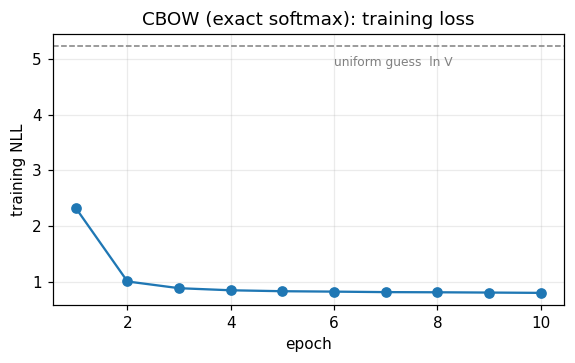

In [13]:
DIM = 50
torch.manual_seed(SEED)
cbow_sm = CBOWSoftmax(V, DIM, PAD)
t0 = time.time()
hist_sm = train(cbow_sm, sent_ids, epochs=10, batch_size=1024, lr=1e-2)
t_sm = time.time() - t0
print(f"training time: {t_sm:.1f}s")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(1, len(hist_sm) + 1), hist_sm, marker="o")
ax.axhline(math.log(V), ls="--", c="gray", lw=1); ax.text(6, math.log(V) - 0.35, "uniform guess  ln V", color="gray", fontsize=8)
ax.set(xlabel="epoch", ylabel="training NLL", title="CBOW (exact softmax): training loss"); plt.show()

The loss cannot reach 0: in a templated corpus several words fit the same context (*the ___ runs in the field* is compatible with ten animals), so there is an irreducible entropy floor.

### 7.5 What did the model learn?

In [14]:
space_sm = EmbeddingSpace(itos, cbow_sm.embeddings, "PyTorch CBOW (softmax)")

def show_neighbours(space, words, k=5):
    for w in words:
        print(f"{w:>8s} → " + ", ".join(f"{n} ({s:.2f})" for n, s in space.most_similar(w, k)))

show_neighbours(space_sm, ["cat", "apple", "train", "paris", "queen", "lynx", "quince"])
print("\nanalogy  man : woman :: king : ?   →", space_sm.analogy("man", "woman", "king", k=3))
print("analogy  france : paris :: italy : ?  →", space_sm.analogy("france", "paris", "italy", k=3))
pd.Series(evaluate(space_sm)).round(3).to_frame(space_sm.name)

     cat → sheep (1.00), dog (1.00), tiger (1.00), bear (1.00), lion (1.00)
   apple → orange (1.00), banana (1.00), cherry (1.00), mango (1.00), peach (1.00)
   train → bike (1.00), car (1.00), bus (1.00), plane (1.00), van (1.00)
   paris → berlin (0.62), madrid (0.57), tokyo (0.54), rome (0.51), cairo (0.50)
   queen → princess (1.00), prince (0.82), king (0.82), sister (0.77), woman (0.77)
    lynx → badger (0.96), cat (0.95), dog (0.94), bear (0.94), fox (0.94)
  quince → guava (0.98), plum (0.98), papaya (0.97), cherry (0.96), peach (0.96)

analogy  man : woman :: king : ?   → ['princess', 'queen', 'sister']
analogy  france : paris :: italy : ?  → ['tokyo', 'spain', 'moscow']


,PyTorch CBOW (softmax)
purity@5 (all),0.942
purity@5 (frequent),1.000
purity@5 (RARE),1.000
analogy top-1 (gender),0.446
analogy top-3 (gender),0.911
analogy top-3 (capital),0.133


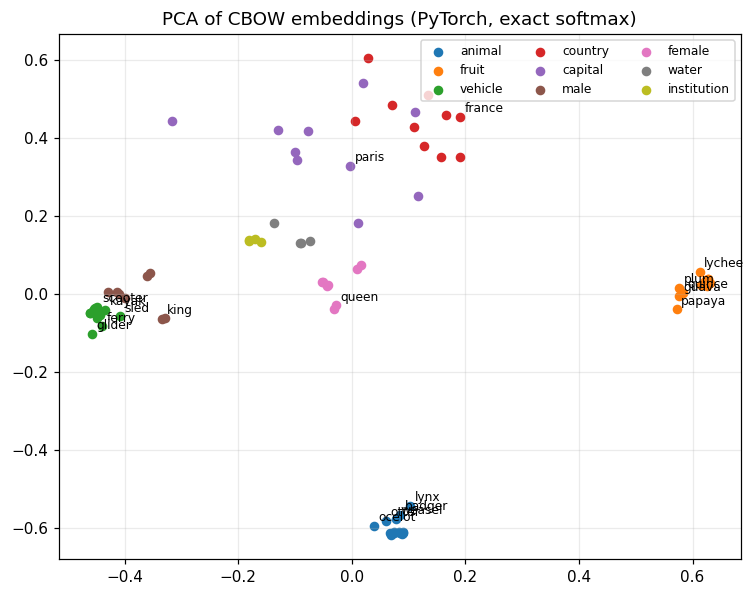

In [15]:
def plot_pca(space, title, cats=("animal", "fruit", "vehicle", "country", "capital", "male", "female", "water", "institution"),
             extra=()):
    """2-D PCA of the labelled words (rare words annotated); `extra` words are drawn as black stars."""
    words = [w for w in space.words if word2cat.get(w) in cats]
    M = space.M[[space.w2i[w] for w in words]]
    pca = PCA(n_components=2, random_state=0).fit(M)
    X = pca.transform(M)
    fig, ax = plt.subplots(figsize=(8, 6.2))
    for i, c in enumerate(cats):
        idx = [k for k, w in enumerate(words) if word2cat[w] == c]
        ax.scatter(X[idx, 0], X[idx, 1], s=28, color=plt.cm.tab10(i), label=c)
    for k, w in enumerate(words):
        if w in RARE or w in ("king", "queen", "paris", "france"):
            ax.annotate(w, X[k], fontsize=8, xytext=(3, 3), textcoords="offset points")
    for w in extra:
        p = pca.transform(space.M[[space.w2i[w]]])[0]
        ax.scatter(*p, marker="*", s=220, c="k"); ax.annotate(w, p, fontsize=10, fontweight="bold", xytext=(6, 6), textcoords="offset points")
    ax.set_title(title); ax.legend(fontsize=8, ncol=3); plt.show()

plot_pca(space_sm, "PCA of CBOW embeddings (PyTorch, exact softmax)")

### 7.6 CBOW with negative sampling in PyTorch
Same encoder, same data, but the $O(Vd)$ softmax is replaced by the $O(Kd)$ objective of §5.2 with $K=5$ noise words.

In [16]:
torch.manual_seed(SEED)
cbow_ns = CBOWNegSampling(V, DIM, PAD, noise_dist=noise, k=5)
t0 = time.time()
hist_ns = train(cbow_ns, sent_ids, epochs=15, batch_size=1024, lr=1e-2, log=False)
t_ns = time.time() - t0
print(f"training time: {t_ns:.1f}s   |   final loss = {hist_ns[-1]:.4f}  (NS loss is on a different scale than the softmax NLL)")
space_ns = EmbeddingSpace(itos, cbow_ns.embeddings, "PyTorch CBOW (neg. sampling)")
show_neighbours(space_ns, ["cat", "apple", "lynx"])

training time: 41.0s   |   final loss = 0.5935  (NS loss is on a different scale than the softmax NLL)
     cat → dog (1.00), cow (1.00), fox (1.00), sheep (1.00), horse (1.00)
   apple → orange (1.00), grape (1.00), peach (1.00), mango (1.00), cherry (1.00)
    lynx → badger (0.94), bear (0.93), cat (0.93), dog (0.93), cow (0.93)


## 8 · Implementation with Gensim

[Gensim](https://radimrehurek.com/gensim/) (Řehůřek & Sojka, 2010) provides the reference, heavily optimised (Cython + BLAS) Word2Vec. One class, `Word2Vec`, covers CBOW (`sg=0`) and Skip-gram (`sg=1`). Mapping of our PyTorch choices to Gensim's hyper-parameters:

| concept | our PyTorch code | Gensim argument |
|---|---|---|
| architecture | CBOW | `sg=0` |
| embedding size $d$ | `DIM` | `vector_size` |
| window radius $c$ | `WINDOW` | `window` |
| dynamic window | mask with $b\sim\mathcal U\{1..c\}$ | `shrink_windows=True` (default, Gensim ≥ 4.1) |
| minimum count | `MIN_COUNT` | `min_count` |
| sub-sampling $t$ | `SUBSAMPLE_T` | `sample` |
| objective | exact softmax / negative sampling | `hs=1` / `negative=K` (here `hs=0, negative=5`) |
| noise distribution | $f^{3/4}$ | `ns_exponent=0.75` |
| mean vs. sum of context | mean | `cbow_mean=1` (default; `0` = sum) |
| optimiser | Adam, mini-batches | SGD, 1 example at a time, `alpha` → `min_alpha` linearly |
| threads | – | `workers` (use `1` for reproducibility) |

Gensim expects an **iterable of tokenised sentences** (`list[list[str]]`) — exactly our `sentences`.

In [17]:
t0 = time.time()
gs_cbow = Word2Vec(
    sentences=sentences,
    vector_size=DIM, window=WINDOW, min_count=MIN_COUNT,
    sg=0,                       # 0 = CBOW
    hs=0, negative=5,           # negative sampling with 5 noise words
    cbow_mean=1,                # average the context vectors
    sample=SUBSAMPLE_T,         # frequent-word sub-sampling threshold
    alpha=0.025, min_alpha=1e-4,
    epochs=20, workers=1, seed=SEED,
)
t_gs = time.time() - t0
print(f"Gensim CBOW trained in {t_gs:.1f}s | vocabulary: {len(gs_cbow.wv)} words (ours: {V}) | "
      f"vectors: {gs_cbow.wv.vectors.shape}")
syn1neg = getattr(gs_cbow, "syn1neg", None)
if syn1neg is not None:
    print("output matrix (syn1neg), the analogue of our U:", syn1neg.shape)

Gensim CBOW trained in 9.6s | vocabulary: 185 words (ours: 185) | vectors: (185, 50)
output matrix (syn1neg), the analogue of our U: (185, 50)


### 8.1 The native Gensim API
Trained vectors live in `model.wv` (a `KeyedVectors` object): `wv.vectors` is the input matrix $W$, `wv.index_to_key` / `wv.key_to_index` map rows to words.

similarity(cat, dog)   = 0.998
similarity(cat, apple) = 0.482
most_similar('lynx')   = [('otter', 0.94), ('weasel', 0.93), ('ocelot', 0.93), ('badger', 0.91), ('wolf', 0.88)]
king - man + woman     = [('princess', 0.99), ('queen', 0.99), ('wife', 0.95)]
odd one out            = apple


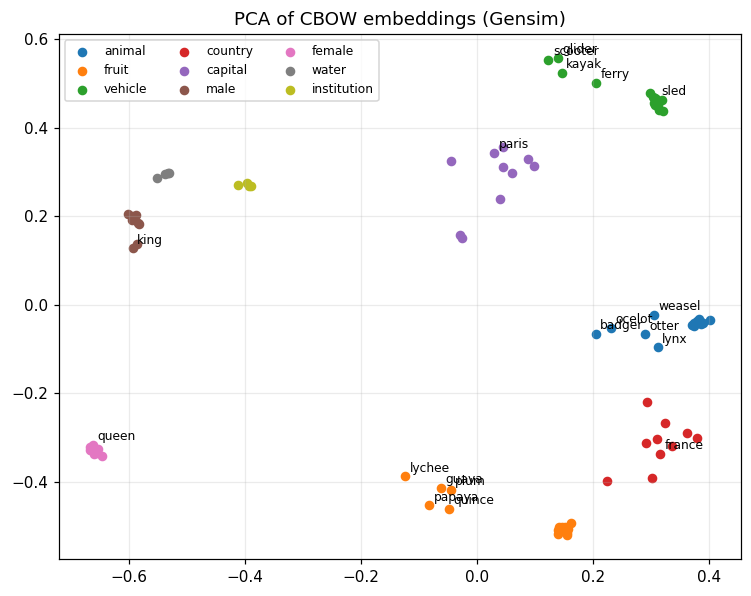

In [18]:
wv = gs_cbow.wv
print("similarity(cat, dog)   =", round(float(wv.similarity("cat", "dog")), 3))
print("similarity(cat, apple) =", round(float(wv.similarity("cat", "apple")), 3))
print("most_similar('lynx')   =", [(w, round(s, 2)) for w, s in wv.most_similar("lynx", topn=5)])
print("king - man + woman     =", [(w, round(s, 2)) for w, s in wv.most_similar(positive=["king", "woman"], negative=["man"], topn=3)])
print("odd one out            =", wv.doesnt_match(["cat", "dog", "apple", "horse"]))

# Persistence:  full model (can resume training)  vs. light-weight vectors only
gs_cbow.save("w2v_cbow.model")
wv.save("w2v_cbow.kv")                       # reload later with:  KeyedVectors.load("w2v_cbow.kv")

gs_space = EmbeddingSpace(wv.index_to_key, wv.vectors, "Gensim CBOW (neg. sampling)")   # same evaluation code as PyTorch
plot_pca(gs_space, "PCA of CBOW embeddings (Gensim)")

## 9 · Side-by-side comparison

Three implementations of the same model family are evaluated with identical code. They are **not** expected to give identical numbers: they differ in objective (exact softmax vs. negative sampling), optimiser (Adam on mini-batches vs. per-example SGD), the gradient scaling of the averaged context (autograd divides by $n_t$; to our knowledge the reference C code, which Gensim ports, applies the error to each context vector undivided), and the exact sub-sampling formula.

In [19]:
results = pd.DataFrame({sp.name: evaluate(sp) for sp in [space_sm, space_ns, gs_space]}).T
results["train time (s)"] = [t_sm, t_ns, t_gs]
results.round(3)

,purity@5 (all),purity@5 (frequent),purity@5 (RARE),analogy top-1 (gender),analogy top-3 (gender),analogy top-3 (capital),train time (s)
PyTorch CBOW (softmax),0.942,1.0,1.0,0.446,0.911,0.133,45.333
PyTorch CBOW (neg. sampling),0.964,1.0,1.0,0.339,0.946,0.211,41.040
Gensim CBOW (neg. sampling),0.964,1.0,1.0,0.429,0.946,0.144,9.585


**How to read the table.** Frequent words in a corpus this regular should be recovered almost perfectly by every variant (purity close to 1); differences appear on the **rare** words and on the **analogies**, which are the harder tests. Timing is only indicative at this scale (Gensim's advantage grows with the corpus because its inner loop is compiled and multi-threaded, whereas on a tiny vocabulary PyTorch is dominated by Python overhead). Re-running with other seeds is a good habit — see the exercises.

## 10 · Limits of CBOW

CBOW is fast and works remarkably well, but its design choices — **averaging**, **one prediction per window**, **one static vector per word type**, **a closed vocabulary**, **a $V$-way softmax** — each impose a limit. Six experiments make them visible; each ends with the remedy it points to.

### 10.1 Limit 1 — The context is a bag: word order is lost
Because $h_t$ is a mean, **any permutation of the context yields exactly the same $h_t$ and therefore exactly the same prediction**. For a language with *dog bites man* ≠ *man bites dog*, CBOW sees the same bag $\{\text{dog},\text{man}\}$ around *bites* in both. (Skip-gram in its basic form also ignores the offset; position-aware variants such as *structured skip-gram*, Ling et al., 2015, address this at the price of more parameters.)

In [20]:
def context_vector(model, words):
    ids = torch.tensor([[stoi[w] for w in words]], device=device)
    with torch.no_grad():
        return model.hidden(ids, torch.ones_like(ids, dtype=torch.bool))[0]

ctx_a = ["the", "dog", "runs", "field"]
ctx_b = ["field", "runs", "the", "dog"]                      # same words, scrambled order
h_a, h_b = context_vector(cbow_sm, ctx_a), context_vector(cbow_sm, ctx_b)
with torch.no_grad():
    p_a, p_b = F.softmax(cbow_sm.out_emb(h_a), -1), F.softmax(cbow_sm.out_emb(h_b), -1)

print("identical context vectors :", torch.allclose(h_a, h_b, atol=1e-6))
print("max |p(.|ctx_a) - p(.|ctx_b)| =", float((p_a - p_b).abs().max()))
print("top prediction for BOTH orders:", itos[int(p_a.argmax())])

identical context vectors : True
max |p(.|ctx_a) - p(.|ctx_b)| = 2.3283064365386963e-10
top prediction for BOTH orders: in


### 10.2 Limit 2 — Averaging bottleneck: one prediction per window, weak signal for rare words
Averaging compresses up to $2c$ vectors into one and makes **a single prediction per window**. Consequences:

* the window is treated as **one observation** — much distributional information is *smoothed over*;
* each context word receives only a $1/n_t$ share of that single gradient, so the **total gradient mass** a word's input vector gets per occurrence is ≈ 1, and its output vector is a prediction target **once** per occurrence;
* in Skip-gram the same occurrence produces $n_t$ separate predictions (≈ $2c$, or the effective average window), each updating the vectors at full strength.

For frequent words this hardly matters — they occur thousands of times. For **rare words** every occurrence is precious. The cell counts, on our corpus and with identical sub-sampling and dynamic window, how much signal each word receives per epoch under both schemes. This is a *mechanical count of gradient events*, not yet an accuracy measurement.

In [21]:
def signal_budget(sent_ids, window, keep_prob, rng):
    """Count, for every word, how much gradient 'signal' it receives per epoch under CBOW vs skip-gram
    (same sub-sampling and the same dynamic window b ~ U{1..c} for both)."""
    cbow_out = np.zeros(V); cbow_in = np.zeros(V); sg_out = np.zeros(V); sg_in = np.zeros(V)
    for sent in sent_ids:
        s = np.asarray(sent); s = s[rng.random(len(s)) < keep_prob[s]]; n = len(s)
        for i in range(n):
            b = rng.integers(1, window + 1)
            nbrs = [j for j in range(max(0, i - b), min(n, i + b + 1)) if j != i]
            if not nbrs:
                continue
            # CBOW: ONE prediction per position: the centre word is the target (1 hit on u_{w_t});
            #       each context vector gets 1/|C| of the gradient  -> total mass on the context words = 1
            cbow_out[s[i]] += 1
            for j in nbrs: cbow_in[s[j]] += 1 / len(nbrs)
            # Skip-gram: |C| predictions per position: the centre vector v_{w_t} is updated |C| times at full
            #            strength, and every context word's output vector is a target once
            sg_in[s[i]] += len(nbrs)
            for j in nbrs: sg_out[s[j]] += 1
    return cbow_in, cbow_out, sg_in, sg_out

cbow_in, cbow_out, sg_in, sg_out = signal_budget(sent_ids, WINDOW, keep_prob, np.random.default_rng(1))
rare_ids = [stoi[w] for w in RARE]; freq_ids = [stoi[w] for w in FREQ_]
budget = pd.DataFrame({
    "occurrences / epoch":      [freq[rare_ids].mean(), freq[freq_ids].mean()],
    "CBOW input-vector mass":   [cbow_in[rare_ids].mean(),  cbow_in[freq_ids].mean()],
    "SKIP input-vector mass":   [sg_in[rare_ids].mean(),    sg_in[freq_ids].mean()],
    "CBOW output-vector hits":  [cbow_out[rare_ids].mean(), cbow_out[freq_ids].mean()],
    "SKIP output-vector hits":  [sg_out[rare_ids].mean(),   sg_out[freq_ids].mean()],
}, index=["rare words", "frequent words"]).round(1)
budget["SKIP / CBOW (input mass)"] = (budget["SKIP input-vector mass"] / budget["CBOW input-vector mass"]).round(1)
print(f"training examples per epoch:  CBOW = {len(tgt):,}   |   skip-gram (centre, context) pairs, full window = {int((ctx != PAD).sum()):,}")
budget

training examples per epoch:  CBOW = 199,013   |   skip-gram (centre, context) pairs, full window = 946,082


,occurrences / epoch,CBOW input-vector mass,SKIP input-vector mass,CBOW output-vector hits,SKIP output-vector hits,SKIP / CBOW (input mass)
rare words,15.5,15.7,53.9,15.5,54.9,3.4
frequent words,592.2,600.4,2062.2,592.2,2074.0,3.4


**Reading.** A rare word with ~15 occurrences gets ~15 units of "input mass" under CBOW but several times more under Skip-gram (the ratio is the average number of context words per position). For a word seen a handful of times, this is the difference between a vector that has moved away from its random initialisation and one that has not. This is the mechanism behind the folklore *"Skip-gram is better for rare words and small data; CBOW is faster and slightly better for frequent words"* (Mikolov et al., 2013a). We test it empirically with Gensim in §11.

### 10.3 Limit 3 — One static vector per word type: polysemy
The word *bank* in our corpus is used both like a **water body** (*we walked along the bank and saw many fish*) and like a **financial institution** (*she opened an account at the bank*). CBOW learns **one** vector for the *type*. Arora et al. (2018) show that such a vector behaves like a frequency-weighted **superposition** of the sense vectors. We measure how far *bank* is from the centroid of each sense cluster, compared with how far the two clusters are from each other.

,"cos(bank, water words)","cos(bank, institutions)","cos(water words, institutions)"
model,,,
PyTorch CBOW (softmax),0.84,0.73,0.38
PyTorch CBOW (neg. sampling),0.83,0.83,0.51
Gensim CBOW (neg. sampling),0.90,0.86,0.64


neighbours of 'bank' (Gensim CBOW):
    bank → stream (0.92), pond (0.92), lake (0.92), treasury (0.86), lender (0.86), broker (0.86), insurer (0.85), river (0.77)


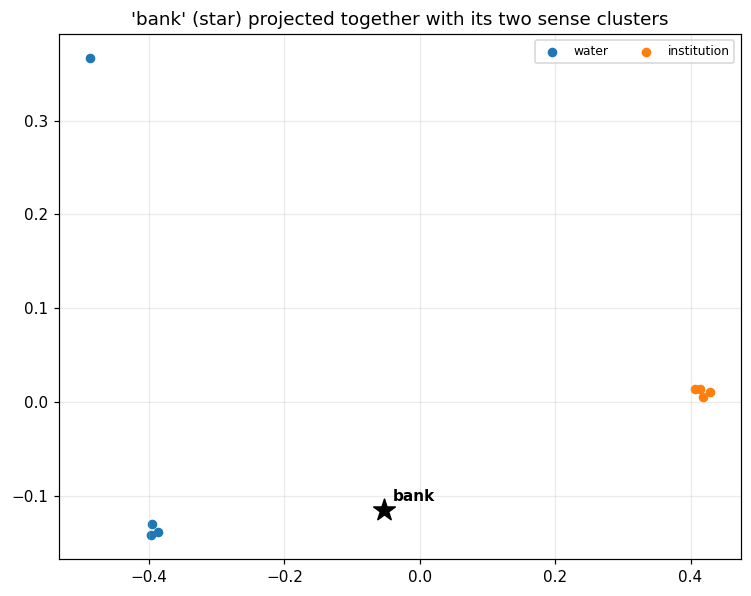

In [22]:
def centroid(space, words):
    v = space.M[[space.w2i[w] for w in words]].mean(0)
    return v / np.linalg.norm(v)

rows = []
for sp in (space_sm, space_ns, gs_space):
    vb = sp.M[sp.w2i["bank"]]
    cw, ci = centroid(sp, relations["water"]), centroid(sp, relations["institution"])
    rows.append({"model": sp.name, "cos(bank, water words)": vb @ cw,
                 "cos(bank, institutions)": vb @ ci, "cos(water words, institutions)": cw @ ci})
display(pd.DataFrame(rows).set_index("model").round(2))

print("neighbours of 'bank' (Gensim CBOW):")
show_neighbours(gs_space, ["bank"], k=8)
plot_pca(gs_space, "'bank' (star) projected together with its two sense clusters", cats=("water", "institution"), extra=("bank",))

**Reading.** Compare the three numbers: if *bank* were monosemous it would be close to one centroid only. In a typical run its neighbours mix words of **both** senses and its vector keeps a substantial cosine with both centroids although the two clusters are far apart (see the star in the 2-D projection): the single vector is a **compromise**. (Exact values vary with the seed and the model.) Downstream, a classifier cannot tell which sense a given occurrence carries. *Remedies:* multi-prototype / sense embeddings, and above all **contextual embeddings** (ELMo, BERT; Peters et al., 2018; Devlin et al., 2019) where the vector depends on the sentence.

### 10.4 Limit 4 — Closed vocabulary and no morphology
Every word type is an atomic symbol. A word never seen in training (or below `min_count`) has **no vector**, and *cat*, *cats*, *cat's* share nothing even though they share most of their form.

In [23]:
for w in ["cats", "lynxes", "kittens"]:
    try:
        wv[w]
    except KeyError as e:
        print(f"{w!r:10s} -> KeyError: {str(e)[:60]}")
print("'cat' in vocabulary:", "cat" in wv, "| 'cats' in vocabulary:", "cats" in wv)

'cats'     -> KeyError: "Key 'cats' not present"
'lynxes'   -> KeyError: "Key 'lynxes' not present"
'kittens'  -> KeyError: "Key 'kittens' not present"
'cat' in vocabulary: True | 'cats' in vocabulary: False


*Remedies:* sub-word models — **fastText** (Bojanowski et al., 2017) represents a word as the sum of its character $n$-gram vectors and can build a vector for any unseen word.

### 10.5 Limit 5 — The $V$-way softmax
The exact objective costs $O(Vd)$ per example in time **and** needs a $B\times V$ logit matrix in memory. The micro-benchmark below times one forward+backward pass of the output layer for growing $V$, exact softmax vs. negative sampling ($K=5$).

In [24]:
def timeit(fn, reps=5):
    fn()                                                       # warm-up
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps): fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps * 1e3             # ms

def bench(Vs=(1_000, 10_000, 50_000), d=100, B=512, K=5):
    rows = []
    for Vb in Vs:
        h = torch.randn(B, d, device=device)
        U = torch.randn(Vb, d, device=device, requires_grad=True)
        y = torch.randint(0, Vb, (B,), device=device)
        def full():
            F.cross_entropy(h @ U.T, y).backward()
        def neg():
            nz = torch.randint(0, Vb, (B, K), device=device)
            s_pos = (h * U[y]).sum(-1)
            s_neg = torch.bmm(U[nz], h.unsqueeze(-1)).squeeze(-1)
            (-(F.logsigmoid(s_pos) + F.logsigmoid(-s_neg).sum(-1)).mean()).backward()
        rows.append({"V": Vb, "exact softmax (ms)": timeit(full), "neg. sampling K=5 (ms)": timeit(neg)})
    return pd.DataFrame(rows).set_index("V").round(2)

bench()

,exact softmax (ms),neg. sampling K=5 (ms)
V,,
1000,7.30,2.29
10000,114.87,4.98
50000,612.49,17.66


The exact softmax grows with $V$, negative sampling does not (up to the cost of indexing). *Remedies:* hierarchical softmax, negative sampling, NCE — they **mitigate** the cost but change what is optimised (negative sampling no longer models $p(w\mid C)$).

### 10.6 Further limits and how they are addressed

| # | limit | symptom | remedy / next step |
|---|---|---|---|
| 1 | context is a bag | *dog bites man* ≡ *man bites dog* | position-aware variants; contextual encoders (RNN, Transformer) |
| 2 | averaging → 1 prediction per window | weak signal for rare words, smoothing of context information | **Skip-gram** (§11) |
| 3 | one vector per type | polysemy collapsed into a compromise | sense embeddings; contextual embeddings (ELMo, BERT) |
| 4 | closed vocabulary, no morphology | OOV words have no vector; *cat*/*cats* unrelated | **fastText** sub-words |
| 5 | $V$-way softmax | $O(Vd)$ time and memory | hierarchical softmax, negative sampling, NCE |
| 6 | purely local window ($c\approx5$) | ignores global co-occurrence statistics and long-range dependencies | GloVe (Pennington et al., 2014); Transformers |
| 7 | trained on raw text | encodes social biases (Bolukbasi et al., 2016) | debiasing, careful corpus curation |
| 8 | many sensitive hyper-parameters | $c$, $d$, $t$, $K$, epochs change results as much as the architecture (Levy et al., 2015) | systematic tuning; report variance over seeds |
| 9 | fragile evaluation | analogy accuracy is noisy, intrinsic ≠ extrinsic quality | evaluate on downstream tasks too |

## 11 · Opening: Skip-gram

Limits 2 and 4 of the table point to the *mirror image* of CBOW. **Skip-gram** reverses the prediction: instead of predicting the centre word from the averaged context, it predicts **each context word from the centre word**.

### 11.1 Formulation

$$\mathcal J_{\text{SG}}=-\frac1T\sum_{t=1}^{T}\ \sum_{\substack{-c\le j\le c\\ j\ne0}}\log p(w_{t+j}\mid w_t),\qquad
p(o\mid i)=\frac{\exp(u_o^{\top}v_i)}{\sum_{k=1}^{V}\exp(u_k^{\top}v_i)} .$$

* **no averaging:** the hidden vector is simply $h=v_{w_t}$ (a lookup);
* the **same** output distribution $p(\cdot\mid w_t)$ is used for all $2c$ context slots (the output matrix is shared; the *offset is ignored*);
* the gradient w.r.t. the centre vector is a **sum** over context words, $\partial L/\partial v_i=\sum_{o\in C}U^{\top}(\hat y-y_o)$ — not an average.

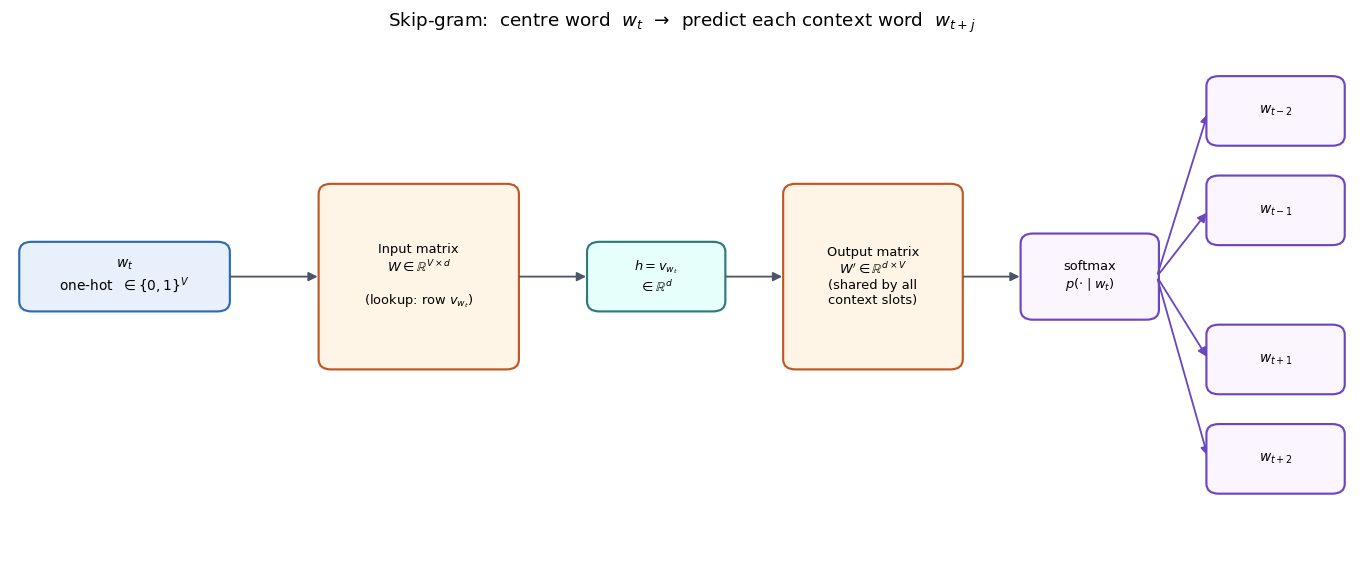

In [25]:
draw_architecture("skipgram")

### 11.2 CBOW and Skip-gram are two views of the same windows
Skip-gram's training pairs are CBOW's examples **unpacked**: each (context, centre) example yields one (centre → context-word) pair per non-padding slot. We can build them from the CBOW arrays in one line.

In [26]:
def cbow_to_skipgram_pairs(ctx, tgt, pad_idx):
    """(N, 2c) contexts + (N,) centres  ->  M pairs (centre, context_word), pads removed."""
    keep = (ctx != pad_idx).ravel()
    centres  = np.repeat(tgt, ctx.shape[1])[keep]
    contexts = ctx.ravel()[keep]
    return centres, contexts

centres, contexts = cbow_to_skipgram_pairs(ctx, tgt, PAD)
print(f"CBOW examples: {len(tgt):,}   →   skip-gram pairs: {len(centres):,}   (×{len(centres) / len(tgt):.1f})")
print("first pairs :", [(itos[a], itos[b]) for a, b in zip(centres[:4], contexts[:4])])

CBOW examples: 199,013   →   skip-gram pairs: 946,082   (×4.8)
first pairs : [('wild', 'sheep'), ('wild', 'sleeps'), ('wild', 'near'), ('wild', 'river')]


### 11.3 Skip-gram with Gensim — does it fix what CBOW struggles with?
The only change is `sg=1`. We train it with the same data and hyper-parameters and compare with CBOW, in particular on the **rare** words and on the analogies.

In [27]:
t0 = time.time()
gs_sg = Word2Vec(
    sentences=sentences, vector_size=DIM, window=WINDOW, min_count=MIN_COUNT,
    sg=1,                                          # 1 = skip-gram
    hs=0, negative=5, sample=SUBSAMPLE_T,
    alpha=0.025, min_alpha=1e-4, epochs=20, workers=1, seed=SEED,
)
t_gs_sg = time.time() - t0
gs_sg_space = EmbeddingSpace(gs_sg.wv.index_to_key, gs_sg.wv.vectors, "Gensim Skip-gram (neg. sampling)")

cmp = pd.DataFrame({sp.name: evaluate(sp) for sp in [gs_space, gs_sg_space]}).T
cmp["train time (s)"] = [t_gs, t_gs_sg]
display(cmp.round(3))
print("rare word 'lynx'  CBOW :", [w for w, _ in gs_space.most_similar("lynx", 4)])
print("rare word 'lynx'  SKIP :", [w for w, _ in gs_sg_space.most_similar("lynx", 4)])

,purity@5 (all),purity@5 (frequent),purity@5 (RARE),analogy top-1 (gender),analogy top-3 (gender),analogy top-3 (capital),train time (s)
Gensim CBOW (neg. sampling),0.964,1.0,1.0,0.429,0.946,0.144,9.585
Gensim Skip-gram (neg. sampling),0.924,1.0,1.0,0.482,1.000,0.433,20.782


rare word 'lynx'  CBOW : ['otter', 'weasel', 'ocelot', 'badger']
rare word 'lynx'  SKIP : ['badger', 'cow', 'bear', 'lion']


**What to expect (and to check).** The usual picture reported in the literature — *Skip-gram* better on rare words and analogies, *CBOW* faster to train — should be visible, but on a toy corpus this regular **the margins can be small and seed-dependent**: do not over-interpret a single run (Exercise 3 asks for variance over seeds). The mechanical advantage of §10.2 is the reason to expect it; the table is the evidence to weigh.

### 11.4 CBOW vs. Skip-gram at a glance

| | **CBOW** | **Skip-gram** |
|---|---|---|
| prediction | centre word ← mean of context | each context word ← centre word |
| input to the output layer | $h=\frac1{n}\sum v_w$ (compressed) | $h=v_{w_t}$ (a single vector) |
| training examples per position | **1** | $\approx n_t$ (up to $2c$) |
| cost per position (hierarchical softmax, Mikolov et al. 2013a) | $nd+d\log_2 V$ | $c\,(d+d\log_2 V)$ |
| training speed | **faster** (several ×) | slower |
| rare words / small corpora | weaker | **stronger** |
| frequent words | slightly better / on par | on par |
| context information | smoothed by averaging | each pair used separately |
| shared limits | static vectors, closed vocabulary, order ignored, local window | same |

### 11.5 Roadmap for the next notebook
1. **Skip-gram from scratch in PyTorch** — full softmax first, then **SGNS** (skip-gram with negative sampling), reusing the data pipeline of §6.
2. **Theory:** SGNS implicitly factorises a shifted PMI matrix (Levy & Goldberg, 2014), linking Word2Vec to count-based methods and GloVe.
3. **Hyper-parameter study** (window, dimension, number of negatives, sub-sampling, context-distribution smoothing; Levy et al., 2015) with variance over seeds.
4. **Scale-up** to text8 with the standard analogy benchmark, then **fastText** for sub-word vectors and a bridge to contextual embeddings.

## 12 · Exercises and references

### Exercises
1. **Sum instead of mean.** In `CBOWBase.hidden`, replace the mean by a sum. How do the loss curve and the neighbour purity change? Relate this to Gensim's `cbow_mean=0`.
2. **Window radius.** Re-train with `window` $\in\{1,2,5,10\}$ (in both PyTorch and Gensim). Which window gives the best purity? Which gives the best analogy score? Explain in terms of *topical* vs. *functional* similarity.
3. **Variance over seeds.** Repeat §11.3 for 5 different `seed` values and report the mean ± standard deviation of purity on the **rare** words for CBOW and Skip-gram. Is the difference significant?
4. **Rarer words.** Edit `make_toy_corpus` so that the rare words occur only 5–6 times (set `min_count` accordingly). Does the CBOW/Skip-gram gap on rare words grow?
5. **Hierarchical softmax.** Train Gensim with `hs=1, negative=0`. Compare quality and time with negative sampling.
6. **Positional CBOW.** Replace the mean by a *position-weighted* sum with one learnable scalar per offset. Does it break the permutation invariance demonstrated in §10.1? Does it help?
7. **Manual gradient for negative sampling.** Derive $\partial\ell/\partial h$ and $\partial\ell/\partial u$ for the loss of §5.2 and check them against autograd as in §4 / §7.2.
8. **Real data.** Replace `sentences` by text8: `import gensim.downloader as api; sentences = [list(s) for s in api.load("text8")]`, with `min_count=5`, `sample=1e-4`, `window=5`, `vector_size=100`. Evaluate with Gensim's built-in benchmark: `from gensim.test.utils import datapath; model.wv.evaluate_word_analogies(datapath("questions-words.txt"))`. (The ground-truth `word2cat`-based metrics of §6.3 apply to the synthetic corpus only.)

### References
* Harris, Z. S. (1954). Distributional structure. *Word*, 10(2–3), 146–162.
* Firth, J. R. (1957). A synopsis of linguistic theory 1930–1955. *Studies in Linguistic Analysis*.
* Bengio, Y., Ducharme, R., Vincent, P., Jauvin, C. (2003). A neural probabilistic language model. *JMLR*, 3, 1137–1155.
* Morin, F., Bengio, Y. (2005). Hierarchical probabilistic neural network language model. *AISTATS*.
* Gutmann, M., Hyvärinen, A. (2010). Noise-contrastive estimation. *AISTATS*.
* Řehůřek, R., Sojka, P. (2010). Software framework for topic modelling with large corpora. *LREC Workshop on New Challenges for NLP Frameworks*.
* **Mikolov, T., Chen, K., Corrado, G., Dean, J. (2013a). Efficient estimation of word representations in vector space. arXiv:1301.3781.**
* **Mikolov, T., Sutskever, I., Chen, K., Corrado, G., Dean, J. (2013b). Distributed representations of words and phrases and their compositionality. *NeurIPS* 26.**
* Goldberg, Y., Levy, O. (2014). word2vec explained: deriving Mikolov et al.'s negative-sampling word-embedding method. arXiv:1402.3722.
* Rong, X. (2014). word2vec parameter learning explained. arXiv:1411.2738.
* Levy, O., Goldberg, Y. (2014). Neural word embedding as implicit matrix factorization. *NeurIPS* 27.
* Pennington, J., Socher, R., Manning, C. D. (2014). GloVe: global vectors for word representation. *EMNLP*.
* Levy, O., Goldberg, Y., Dagan, I. (2015). Improving distributional similarity with lessons learned from word embeddings. *TACL*, 3, 211–225.
* Ling, W., Dyer, C., Black, A., Trancoso, I. (2015). Two/too simple adaptations of word2vec for syntax problems. *NAACL*.
* Bolukbasi, T., Chang, K.-W., Zou, J., Saligrama, V., Kalai, A. (2016). Man is to computer programmer as woman is to homemaker? Debiasing word embeddings. *NeurIPS* 29.
* Bojanowski, P., Grave, E., Joulin, A., Mikolov, T. (2017). Enriching word vectors with subword information. *TACL*, 5, 135–146.
* Arora, S., Li, Y., Liang, Y., Ma, T., Risteski, A. (2018). Linear algebraic structure of word senses, with applications to polysemy. *TACL*, 6, 483–495.
* Peters, M. et al. (2018). Deep contextualized word representations. *NAACL*.
* Devlin, J., Chang, M.-W., Lee, K., Toutanova, K. (2019). BERT: pre-training of deep bidirectional transformers for language understanding. *NAACL*.
* Paszke, A. et al. (2019). PyTorch: an imperative style, high-performance deep learning library. *NeurIPS* 32.